<a href="https://colab.research.google.com/github/Prakash9188/EfficientSeg-CES/blob/main/LAB12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 12: Neural Networks
Course: Introduction to Machine Learning






## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand fundamental PyTorch concepts (Tensors, Autograd, and Modules) and Activation functions.
2. Apply data augmentations (rotation, scaling) on standard datasets like FashionMNIST.
3. Compare the mathematical behavior and application of different loss functions.
4. Analyze the parameter efficiency of ANNs vs. CNNs on spatial data.
5. Understand the theory and implementation of backpropagation.
6. Extract and visualize activation maps from deep neural network layers.

## 1. Fundamentals of PyTorch
Before diving into complex networks, let us review the basic building blocks of PyTorch: Tensors, operations, and Automatic Differentiation (`autograd`).

### 1.1 What is a Tensor?
A **Tensor** is the fundamental data structure in PyTorch. Conceptually, a tensor is a multi-dimensional grid of numbers (an array) that shares many similarities with NumPy's `ndarray`. However, PyTorch tensors have two critical advantages that make them suitable for deep learning:
1. **GPU Acceleration**: They can run on specialized hardware accelerators (like GPUs and TPUs) to speed up computations by orders of magnitude compared to CPUs.
2. **Automatic Differentiation**: They keep track of the operations performed on them, allowing PyTorch to automatically compute gradients (derivatives) for optimization.

### 1.2 Tensor Dimensionality & Representation
Tensors are classified by their number of dimensions, also known as their **rank** or **axes**:
* **Rank 0 (Scalar)**: A single number. Shape: `[]`. Example: `torch.tensor(5.0)`
* **Rank 1 (Vector)**: A 1D array of numbers. Shape: `[D]`. Example: `torch.tensor([1.0, 2.0, 3.0])`
* **Rank 2 (Matrix)**: A 2D grid of numbers with rows and columns. Shape: `[Rows, Cols]`. Example: `torch.tensor([[1, 2], [3, 4]])`
* **Rank N (N-Dimensional Tensor)**: High-dimensional arrays. In deep learning, images are represented as Rank 3 tensors: `[Channels, Height, Width]`, e.g., `[3, 224, 224]` for a standard RGB image.

### 1.3 The Concept of Batch Size
When training machine learning models, we rarely process a single image or data point at a time due to hardware efficiency and optimization stability. Instead, we group multiple samples together into a **batch**.

* **Batch Size**: The number of training examples processed together in one single forward and backward pass.
* **The Batch Dimension**: PyTorch models expect input data to have an explicit batch dimension as the very first dimension (axis 0).
  * For example, a single grayscale image from FashionMNIST has a shape of `[1, 28, 28]` (Channels, Height, Width).
  * When loaded into a batch of size **64**, the tensor's shape becomes `[64, 1, 28, 28]` (Batch Size, Channels, Height, Width).
* **Why Use Batches?**
  * **Vectorization**: Modern GPUs leverage parallel processing architectures to perform math on a batch of 64 images almost as quickly as on a single image.
  * **Gradient Estimation**: Updating model weights based on the average gradient of a batch (Mini-batch Gradient Descent) provides a much more stable and accurate estimate of the true gradient than updating after every individual sample.

### 1.4 Memory Layout & Device Management
Tensors can reside in different physical memory spaces:
* **`cpu`**: Default system memory. Operations are executed on the host processor.
* **`cuda`** (or `mps` on Apple Silicon): GPU memory. To utilize a GPU, you must explicitly transfer your tensors using `.to('cuda')` or `.cuda()`. All interacting tensors in a mathematical operation must reside on the same physical device.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# 1. Tensor creation and operations
x = torch.tensor([[1.0, 2.0], [3.0, 4.0]], requires_grad=True)
print("Tensor x:\n", x)

# 2. Forward pass
y = x ** 2 + 3 * x
out = y.______() #output is mean of outputs of forward pass(y)
print("\nOutput (mean of y):", out)

# 3. Backward pass (Autograd)
out.backward()
print("\nGradients dy/dx:\n", x.grad)

Tensor x:
 tensor([[1., 2.],
        [3., 4.]], requires_grad=True)

Output (mean of y): tensor(15., grad_fn=<MeanBackward0>)

Gradients dy/dx:
 tensor([[1.2500, 1.7500],
        [2.2500, 2.7500]])


## 1.1 Understanding Activation Functions

Activation functions introduce non-linear properties to neural networks, allowing them to learn complex patterns and fit non-linear decision boundaries. Without them, a neural network, regardless of the number of layers, would behave like a simple single-layer linear regression model.

Here are the most commonly used activation functions, their mathematical formulas, and where they should be applied:

### 1. Sigmoid Activation
* **Formula**:
  $$\sigma(z) = \frac{1}{1 + e^{-z}}$$
* **Output Range**: $(0, 1)$
* **Characteristics**: Maps inputs to a probability-like scale. However, it suffers from **vanishing gradients** for very high or very low inputs, where the curve saturates and the derivative approaches zero.
* **Use Cases**: Typically restricted to the output layer of **binary classification** models.

### 2. Hyperbolic Tangent (Tanh) Activation
* **Formula**:
  $$\tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$$
* **Output Range**: $(-1, 1)$
* **Characteristics**: Zero-centered, which means negative inputs map to negative outputs and positive inputs map to positive outputs. This often makes optimization easier than Sigmoid, but it still suffers from vanishing gradients when saturated.
* **Use Cases**: Commonly used in hidden layers of Recurrent Neural Networks (RNNs).

### 3. Rectified Linear Unit (ReLU)
* **Formula**:
  $$f(z) = \max(0, z)$$
* **Output Range**: $[0, \infty)$
* **Characteristics**: Extremely computationally efficient since it only requires thresholding at zero. It helps mitigate the vanishing gradient problem in deep networks. However, it can suffer from the **"Dying ReLU"** problem where neurons get stuck outputting zero and stop updating entirely.
* **Use Cases**: The default choice for hidden layers in modern deep architectures like MLPs and CNNs.

### 4. Leaky ReLU
* **Formula**:
  $$f(z) = \max(\alpha z, z)$$
  *(where $\alpha$ is a small constant, e.g., $0.01$)*
* **Output Range**: $(-\infty, \infty)$
* **Characteristics**: Prevents the "Dying ReLU" problem by ensuring that even negative inputs retain a small, non-zero gradient.
* **Use Cases**: Used in deep networks where many neurons are dying, and extensively in Generative Adversarial Networks (GANs).

### 5. Softmax Activation
* **Formula**:
  $$\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{C} e^{z_j}}$$
* **Output Range**: $(0, 1)$ (where all outputs sum up to 1)
* **Characteristics**: Converts a vector of raw scores (logits) into a probability distribution over multiple classes.
* **Use Cases**: Exclusively used in the **output layer of multi-class classification** tasks (such as FashionMNIST).

### 1.1.1 Student Practice: Implementing & Using Activation Functions
In this exercise, you will practice implementing basic activation functions from scratch using pure PyTorch mathematical operations, and compare them with PyTorch's built-in functions.

In [ ]:
import torch
import torch.nn as nn

# Input data for testing your implementations
test_input = torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])

# --- 1. Sigmoid Activation from scratch and PyTorch ---
def manual_sigmoid(x):
    # TODO: Implement the Sigmoid formula from scratch using torch.exp()
    return _______________

# TODO: Apply PyTorch's built-in functional sigmoid to test_input
practice_sigmoid_pytorch = torch.sigmoid(test_input)

print("Manual Sigmoid output:", manual_sigmoid(test_input))
print("PyTorch Sigmoid output:", practice_sigmoid_pytorch)

# --- 2. ReLU Activation from scratch and PyTorch ---
def manual_relu(x):
    # TODO: Implement the ReLU formula from scratch using torch.clamp() or torch.maximum() on (torch.tensor(0.0), x)
    return ____________

# TODO: Instantiate PyTorch's nn.ReLU module and pass test_input through it
relu_module = nn.ReLU()
practice_relu_pytorch = relu_module(test_input)

print("\nManual ReLU output:", manual_relu(test_input))
print("PyTorch ReLU output:", practice_relu_pytorch)

Manual Sigmoid output: tensor([0.1192, 0.3775, 0.5000, 0.7311, 0.9526])
PyTorch Sigmoid output: tensor([0.1192, 0.3775, 0.5000, 0.7311, 0.9526])

Manual ReLU output: tensor([0., 0., 0., 1., 3.])
PyTorch ReLU output: tensor([0., 0., 0., 1., 3.])


### 1.1.2 TODO: Manual Tanh and Leaky ReLU
Now, practice implementing **Tanh** and **Leaky ReLU** from scratch and verify your results against PyTorch's built-in methods.

In [ ]:
import torch
import torch.nn as nn

# Input data for testing your implementations
test_input_adv = torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])

# --- 3. Tanh Activation from scratch and PyTorch ---
def manual_tanh(x):
    # TODO: Implement the Tanh formula from scratch using torch.exp()
    # Hint: recall tanh(x)
    exp_x = torch.exp(x)
    exp_neg_x = torch.exp(-x)
    return _________________

# TODO: Apply PyTorch's built-in functional tanh to test_input_adv
practice_tanh_pytorch = torch.tanh(test_input_adv)

print("Manual Tanh output:", manual_tanh(test_input_adv))
print("PyTorch Tanh output:", practice_tanh_pytorch)

# --- 4. Leaky ReLU Activation from scratch and PyTorch ---
def manual_leaky_relu(x, alpha=0.01):
    # TODO: Implement the Leaky ReLU formula from scratch using torch.maximum() or element-wise conditions
    # Hint: Return x where x > 0, and alpha * x where x <= 0
    return _____________

# TODO: Instantiate PyTorch's nn.LeakyReLU module with negative_slope=0.01 and pass test_input_adv through it
leaky_relu_module = nn.LeakyReLU(negative_slope=0.01)
practice_leaky_relu_pytorch = leaky_relu_module(test_input_adv)

print("\nManual Leaky ReLU output:", manual_leaky_relu(test_input_adv, alpha=0.01))
print("PyTorch Leaky ReLU output:", practice_leaky_relu_pytorch)

Manual Tanh output: tensor([-0.9640, -0.4621,  0.0000,  0.7616,  0.9951])
PyTorch Tanh output: tensor([-0.9640, -0.4621,  0.0000,  0.7616,  0.9951])

Manual Leaky ReLU output: tensor([-0.0200, -0.0050,  0.0000,  1.0000,  3.0000])
PyTorch Leaky ReLU output: tensor([-0.0200, -0.0050,  0.0000,  1.0000,  3.0000])


## 2. Dataset Preparation & Augmentation
We will use the **FashionMNIST** dataset. To make our models robust to spatial variances, we apply **Data Augmentation** techniques such as random rotation, scaling (via RandomAffine), and horizontal flips.

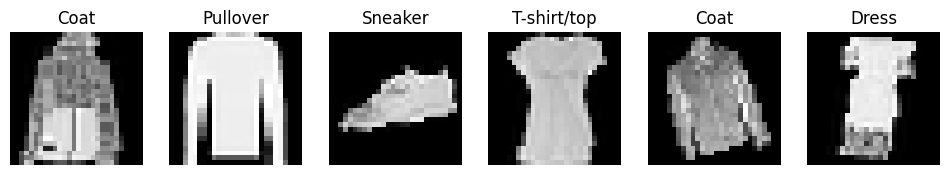

In [ ]:
# Define training transformations with augmentations
train_transform = transforms.Compose([
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, scale=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Define test transformations (no augmentation, only normalization)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download and load FashionMNIST
train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=train_transform)
test_dataset = ___________________(root='./data', train=False, download=True, transform=test_transform) #fill in the TODO

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=__, shuffle=True) #Your Batch Size is 64
test_loader = torch.utils.data._________(test_dataset, batch_size=__, shuffle=False) #fill to run

# Visualize some augmented samples
images, labels = next(iter(train_loader))
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i in range(6):
    img = images[i].squeeze().numpy() * 0.5 + 0.5 # unnormalize
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(classes[labels[i]])
    axes[i].axis('off')
plt.show()

### 2.1 Student Practice: Dataset & Augmentation on Toy Data
To reinforce your understanding of PyTorch transforms and DataLoaders, complete the simple exercises below on a small toy dataset containing random synthetic images.

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

# 1. Define a basic custom Dataset of 10 random 'images' of shape (1, 8, 8)
class ToyDataset(Dataset):
    def __init__(self):
        self.data = torch.randn(10, 1, 8, 8)
        self.labels = torch.randint(0, 2, (10,))

    def __len__(self):
        # TODO: Return the total number of samples (10)
        return _______

    def __getitem__(self, idx):
        # TODO: Return the image and its corresponding label at the given index
        return _______

toy_dataset = ToyDataset()

# 2. Complete the DataLoader instantiation
# TODO: Create a DataLoader with batch_size=2 and shuffling enabled
toy_loader = DataLoader(toy_dataset, batch_size=__, shuffle=__)

# Verification
for batch_images, batch_labels in toy_loader:
    print("Batch images shape:", batch_images.shape)
    print("Batch labels:", batch_labels)
    break

ValueError: batch_size should be a positive integer value, but got batch_size=

## 3. Understanding Loss Functions

Let's evaluate how different standard loss functions compute penalties for multiclass classification tasks, including their mathematical definitions and typical use cases:

### 1. Cross-Entropy Loss
* **Formula**:
  $$L = -\sum_{c=1}^{C} y_c \log(\hat{y}_c)$$
  Where $C$ is the number of classes, $y_c$ is the binary indicator (0 or 1) indicating if class label $c$ is the correct classification, and $\hat{y}_c$ is the predicted probability (softmax output) for class $c$.
* **Use Cases**:
  * Standard for multi-class classification problems (e.g., classifying images in FashionMNIST or CIFAR-10).
  * Best suited when classes are mutually exclusive.

### 2. Mean Squared Error (MSE) Loss
* **Formula**:
  $$L = \frac{1}{C} \sum_{c=1}^{C} (y_c - \hat{y}_c)^2$$
  Where $y_c$ is the target value (often one-hot encoded for classification) and $\hat{y}_c$ is the predicted model output.
* **Use Cases**:
  * Primary loss function for regression tasks predicting continuous numeric values.
  * Sometimes used in classification alongside a Sigmoid/Softmax layer for specific probabilistic modeling or deep generative models (like Autoencoders), though generally less effective than Cross-Entropy for pure classification.

### 3. Multi-Margin Loss (Hinge Loss for Multiclass)
* **Formula**:
  $$L = \frac{1}{C} \sum_{i \neq y} \max(0, \Delta + s_i - s_y)$$
  Where $s$ are the scores (logits) predicted by the model, $s_y$ is the score of the correct class, and $\Delta$ is the margin (typically $\Delta = 1$).
* **Use Cases**:
  * Used in multi-class Support Vector Machines (SVMs) and maximum-margin classifiers.
  * Useful when you want to penalize predictions that are correct but not confident enough (within the margin distance $\Delta$ from other classes).

In [ ]:
# Simulated raw model outputs (logits) for 3 classes, batch_size = 2
logits = torch.tensor([[2.0, 0.5, -1.0], [0.1, 1.2, 3.5]], requires_grad=True)
targets = torch.tensor([0, 2]) # True classes

# 1. Cross Entropy Loss
ce_loss_fn = nn._______() #Use the CrossEntropyLoss
ce_loss = ce_loss_fn(logits, targets)
print(f"CrossEntropy Loss: {ce_loss.item():.4f}")

# 2. Mean Squared Error (requires one-hot target processing)
one_hot_targets = torch.nn.functional.one_hot(targets, num_classes=3).float()
mse_loss_fn = nn.______() #Use MSELoss
mse_loss = mse_loss_fn(torch.softmax(logits, dim=1), one_hot_targets)
print(f"MSE Loss (on Softmax probabilities): {mse_loss.item():.4f}")

# 3. Multi-Margin Loss
margin_loss_fn = nn.MultiMarginLoss(margin=1.0)
margin_loss = margin_loss_fn(logits, targets)
print(f"Multi-Margin Loss: {margin_loss.item():.4f}")

CrossEntropy Loss: 0.1834
MSE Loss (on Softmax probabilities): 0.0168
Multi-Margin Loss: 0.0000


## 4. Model Architectures & Parameter Comparison

### Why CNNs perform better than ANNs (MLPs) on Image Data:
- **Parameter Explosion**: An MLP flattens input images ($28 \times 28 = 784$ features). A single hidden layer of 512 neurons results in $784 \times 512 \approx 400,000$ connections. For larger high-resolution images, this scales poorly.
- **Spatial Relationships**: MLPs lose structural spatial information when flattening. CNNs leverage shared weights (kernels) to preserve spatial features using localized receptive fields.

In [ ]:
# Multilayer Perceptron (ANN)
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )
    def forward(self, x):
        return self.network(x)

# Convolutional Neural Network (CNN)
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), # Output: 16 x 28 x 28
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                         # Output: 16 x 14 x 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1),# Output: 32 x 14 x 14
            nn.____(), #Use ReLU activation
            nn.MaxPool2d(2, 2)                          # Output: 32 x 7 x 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.____(), # Use ReLU
            nn.________(128, 10) #TODO: Use Linear Activation Functions
        )
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

mlp_model = ______() # Use the required Model i.e Call the right function
cnn_model = ______() # Use the required Model i.e Call the right function

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Trainable Parameters in MLP: {count_parameters(mlp_model):,}")
print(f"Total Trainable Parameters in CNN: {count_parameters(cnn_model):,}")

Total Trainable Parameters in MLP: 535,818
Total Trainable Parameters in CNN: 206,922


### 4. TODO: Building and Analyzing a 2-Layer Neural Network
Let's apply what you have learned about model architectures! In this exercise, you will complete the implementation of a simple 2-layer Neural Network (Multi-Layer Perceptron) designed to classify 1D synthetic feature vectors.

In [ ]:
import torch
import torch.nn as nn

# Define a simple 2-layer Neural Network
class SimpleTwoLayerNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleTwoLayerNN, self).__init__()
        # TODO: Define the first linear layer (input to hidden)
        self.fc1 = nn.Linear(________, ________)

        # TODO: Define the activation function (use ReLU)
        self.relu = nn.______()

        # TODO: Define the second linear layer (hidden to output)
        self.fc2 = nn.Linear(________, ________)

    def forward(self, x):
        # TODO: Complete the forward pass sequence: fc1 -> relu -> fc2
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Instantiate the model with: input_size=10, hidden_size=20, output_size=2
# TODO: Fill in the correct settings below
student_model = SimpleTwoLayerNN(input_size=__, hidden_size=__, output_size=__)

# Verify your network parameters
def check_parameters(model):
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Trainable Parameters in your 2-Layer NN: {total_params}")

# Note: With input=10, hidden=20, output=2, you should expect 262 parameters!
check_parameters(student_model)

NameError: name '________' is not defined

## 5. Backpropagation: Mathematical Theory & Implementation

Backpropagation is the core algorithm used to train neural networks. It computes the gradients of the loss function with respect to each weight using the mathematical **Chain Rule** of calculus, which are then used by an optimizer to update the network parameters.

### Backpropagation Steps:
1. **Forward Pass**: Feed inputs through the model layers to get a prediction $\hat{y}$.
2. **Loss Calculation**: Evaluate prediction error using a loss function $L(\hat{y}, y)$.
3. **Backward Pass**: Apply the Chain Rule starting from the output layer back to the input layer to compute partial derivatives:
   $$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial \hat{y}} \times \frac{\partial \hat{y}}{\partial z} \times \frac{\partial z}{\partial w}$$
4. **Optimization**: Update the parameters in the direction opposite to the gradient to minimize the loss:
   $$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$
   *(where $\eta$ is the learning rate)*

# Manual demonstration of backpropagation


In [ ]:
x = torch.tensor([1.5], requires_grad=True)
w = torch.tensor([0.8], requires_grad=True)
b = torch.tensor([0.2], requires_grad=True)
y_true = torch.tensor([2.0])

print("=== Forward Pass ===")
# Linear combination
z = _________  # TODO: Fill in with the linear output formula. Hint: Recall Simple Linear Regression
# Prediction
y_pred = torch.sigmoid(z)
print(f"Predicted value: {y_pred.item():.4f}")

# Binary Cross Entropy Loss
loss = - (y_true * torch.log(y_pred) + (1.0 - y_true) * torch.log(1.0 - y_pred))
print(f"Loss: {loss.item():.4f}")

print("\n=== Backward Pass ===")
loss.__________() # TODO: Fill in for the backward Pass Hint: Recall how we used to perform Backward Pass from Above cells

print(f"Gradient of Loss w.r.t Weight (w): {w.grad.item():.4f}")
print(f"Gradient of Loss w.r.t Bias (b): {b.grad.item():.4f}")
print(f"Gradient of Loss w.r.t Input (x): {x.grad.item():.4f}")

=== Forward Pass ===
Predicted value: 0.8022
Loss: -1.1796

=== Backward Pass ===
Gradient of Loss w.r.t Weight (w): -1.7967
Gradient of Loss w.r.t Bias (b): -1.1978
Gradient of Loss w.r.t Input (x): -0.9583


### 5.0.1 TODO: Backpropagation on the 2-Layer Neural Network
Let's apply backpropagation theory to the simple 2-layer network you created in Section 4.1! In this exercise, you will complete the code to calculate loss, run the backward pass, and update the model weights using a synthetic batch of data.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Let's recreate the network for this exercise block
class SimpleTwoLayerNN(nn.Module):
    def __init__(self, input_size=10, hidden_size=20, output_size=2):
        super(SimpleTwoLayerNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        return self.fc2(self.relu(self.fc1(x)))

# 1. Instantiate the model, an optimizer, and a loss function
practice_model = SimpleTwoLayerNN()
# TODO: Initialize an SGD optimizer for practice_model's parameters with a learning rate of 0.05
practice_optimizer = optim.SGD(________________________, lr=0.05)

# TODO: Instantiate the CrossEntropyLoss function
practice_criterion = nn._________________()

# Generate a synthetic mini-batch: 4 samples of 10-dimensional features
synthetic_input = torch.randn(4, 10)
synthetic_targets = torch.tensor([0, 1, 0, 1])  # Target classes

# 2. Forward Pass
# TODO: Pass the input through your model to get predictions (logits)
synthetic_outputs = practice_model(_________________)

# 3. Calculate Loss
# TODO: Compute the loss using your criterion
practice_loss = practice_criterion(_________________, synthetic_targets)
print(f"Initial Practice Loss: {practice_loss.item():.4f}")

# 4. Backward Pass & Weight Update
# TODO: Clear out old gradients in the optimizer
practice_optimizer._________________()

# TODO: Trigger PyTorch Autograd to compute gradients (Backward pass)
practice_loss._________________()

# Check if gradient was successfully computed on fc1 weights
fc1_grad_norm = practice_model.fc1.weight.grad.norm().item()
print(f"fc1 Layer Gradient Norm: {fc1_grad_norm:.4f}")

# TODO: Perform a step with the optimizer to update the network weights
practice_optimizer._________________()
print("Optimization step completed successfully!")

NameError: name '________________________' is not defined

### 5.1 Backpropagation on the FashionMNIST Models
Now, let us perform backpropagation on the actual models we defined earlier (`MLP` and `CNN`) using a real batch of data from the `train_loader`. We will use standard Cross-Entropy loss and the SGD optimizer to perform the backward pass and update the weights.

In [ ]:
# Fetch a single batch of real data
images, labels = next(iter(train_loader))

# Instantiate the MLP model, loss function, and optimizer
model = ________() # TODO: Hint: Call your Model
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# --- Step 1: Forward Pass ---
outputs = model(images)
loss = criterion(_______, labels) # TODO: Fill in with correct statements to calculate the loss
print(f"Initial batch loss: {loss.item():.4f}")

# --- Step 2: Zero the gradients ---
optimizer.zero_grad()

# Check a sample parameter's gradient before backward
sample_parameter = list(model.parameters())[0]
print("Gradient of the first layer weights before backpropagation (min/max):",
      sample_parameter.grad.min().item() if sample_parameter.grad is not None else "None")

# --- Step 3: Backward Pass (Backpropagation) ---
loss.______() #TODO: Perform Backward Pass

print("Gradient of the first layer weights after backpropagation (min/max):",
      f"{sample_parameter.grad.min().item():.6f} / {sample_parameter.grad.max().item():.6f}")

# --- Step 4: Optimizer Step ---
optimizer.step()
print("Weights updated successfully!")

Initial batch loss: 2.2932
Gradient of the first layer weights before backpropagation (min/max): None
Gradient of the first layer weights after backpropagation (min/max): -0.005941 / 0.005111
Weights updated successfully!


## 5.2 Limitations of Backpropagation & Alternative Methods

While backpropagation is the cornerstone of modern deep learning, it possesses several theoretical, practical, and biological limitations.

### 1. Key Limitations of Backpropagation
* **Vanishing & Exploding Gradients**: As gradients are backpropagated through many layers via chain-rule multiplications, they can exponentially decrease to zero (preventing early layers from learning) or scale infinitely (causing training instability).
* **High Computational and Memory Footprint**: Backpropagation requires storing all intermediate layer activations in memory during the forward pass so they can be reused during the backward pass. This makes training extremely memory-intensive.
* **Local Minima and Saddle Points**: Non-convex optimization landscapes can trap gradient descent variants in suboptimal local minima or plateaus.
* **Biological Implausibility**: The human brain does not use backpropagation. The brain cannot freeze its state, pass error signals backward through exact symmetric weight pathways (the "weight transport problem"), or rely on global synchronization.


## 6. Visualizing Activation Maps
To understand what features the CNN is learning, we can extract and visualize the output (activation map) of the first convolutional layer after a forward pass.

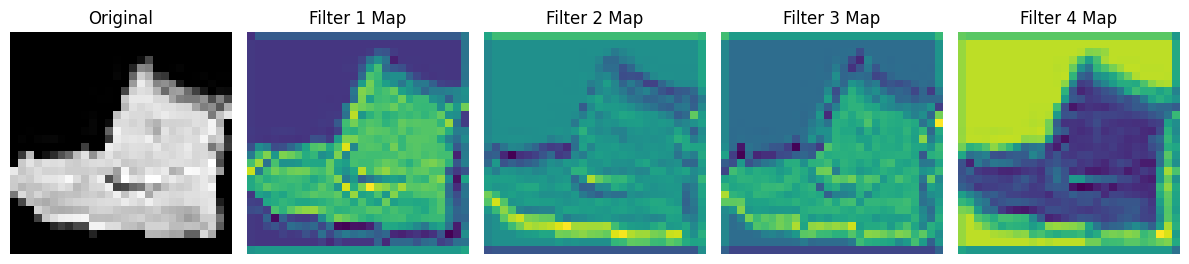

In [ ]:
# Get a single image from the dataset
sample_image, _ = train_dataset[0]
sample_image = sample_image.unsqueeze(0) # Add batch dimension: [1, 1, 28, 28]

# Extract the output of the first convolutional layer
first_conv_layer = cnn_model.features[0]

with torch.no_grad():
    activation_map = first_conv_layer(sample_image)

# Plot original image alongside the learned activation maps
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
axes[0].imshow(sample_image.squeeze(), cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

for i in range(4):
    axes[i+1].imshow(activation_map[0, i].numpy(), cmap='viridis')
    axes[i+1].set_title(f"Filter {i+1} Map")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

### 6.1  TODO: Understanding and Reversing transforms.Normalize

In our data pipeline, we transformed images using:
`transforms.Normalize((0.5,), (0.5,))`

In this exercise, you will manually compute normalization on a mini-tensor and implement the inverse operation to reconstruct normalized pixels back into standard viewable images ($[0, 1]$ or $[0, 255]$ range).

In [ ]:
import torch

# Let's create a simulated single-channel pixel tensor with values from 0 to 1
toy_pixels = torch.tensor([0.0, 0.25, 0.5, 0.75, 1.0])

# TODO: Normalize the toy_pixels manually using mean=0.5 and std=0.5
# Formula: normalized = (input - mean) / std
mean = 0.5
std = 0.5
normalized_pixels = (toy_pixels - ________) / ________
print("Normalized Pixels:", normalized_pixels)

# TODO: Reconstruct the original pixel values from normalized_pixels
# Hint: Rearrange the normalization formula to solve for the original input
reconstructed_pixels = (normalized_pixels * ________) + ________
print("Reconstructed Pixels:", reconstructed_pixels)

# Check if your reconstruction matches the original toy_pixels
assert torch.allclose(toy_pixels, reconstructed_pixels), "Reconstruction mismatch! Check your algebra."
print("Perfect reconstruction! Verification passed!")

NameError: name '________' is not defined

## 7. EXCERCISES: Multi-Activation Networks & MNIST Visualization

This final section contains advanced practical challenges to test your understanding of customized activation routing, backpropagation calculations, and reproducible spatial representation learning.

### Exercise 1: Multi-Activation Hidden Layer
Complete the custom neural network below. The hidden layer must have 3 neurons, each applying a different activation function to its linear combination:
- Neuron 1: **ReLU**
- Neuron 2: **Sigmoid**
- Neuron 3: **Tanh**

The outputs of these 3 neurons are then passed to the output layer (2 neurons), followed by a **linear** (no-op) activation.

In [ ]:
import torch
import torch.nn as nn

class CustomMultiActivationNN(nn.Module):
    def __init__(self):
        super(CustomMultiActivationNN, self).__init__()
        # We have 1D input of size 4
        # 3 individual neurons in hidden layer modeled as 3 separate linear outputs of size 1
        self.neuron1_fc = nn.Linear(4, 1)
        self.neuron2_fc =
        self.neuron3_fc =

        # Output layer takes the 3 concatenated activations and maps to 2 outputs
        self.output_fc =

    def forward(self, x):
        # TODO: Compute the linear combination and apply specific activation for each neuron
        # Neuron 1 -> ReLU
        n1 = torch.relu(self.neuron1_fc(x))

        # Neuron 2 -> Sigmoid
        n2 =

        # Neuron 3 -> Tanh
        n3 =

        # TODO: Concatenate the 3 outputs along the feature dimension (dim=1) to feed into the 2nd layer


        # TODO: Compute output layer (no-op/linear activation)
        out = self.output_fc(________)
        return out

# Verification
toy_x = torch.randn(1, 4)
model_ex1 = CustomMultiActivationNN()
output_ex1 = model_ex1(toy_x)
print("Output shape (expected [1, 2]):", output_ex1.shape)

NameError: name '________' is not defined

### Exercise 2: Backpropagation on the Custom Multi-Activation Network
Now, perform backpropagation on the network you constructed in Exercise 1 using a simple Mean Squared Error (MSE) loss.

In [ ]:
# Define target value for our batch
toy_target = torch.tensor([[1.0, 0.0]])

# Initialize loss function. READ THE QUESTION FOR WHICH LOSS FUNCTION WE ARE USING
criterion_mse =

# Zero out any existing gradients. Apply zero_grad()
model_ex1.___________

# Forward pass on toy_x
predictions = model_ex1(toy_x)

# TODO: Calculate MSE loss between predictions and toy_target
loss_ex2 = criterion_mse(________, ________)
print(f"Exercise 2 Loss: {loss_ex2.item():.4f}")

# TODO: Run the backward pass to compute gradients
loss_ex2.__________()

# Check if gradients were successfully computed for the first neuron
print("Neuron 1 Gradient computed:", model_ex1.neuron1_fc.weight.grad is not None)

NameError: name '________' is not defined

### Exercise 3: Reproducible 2-Layer MNIST Activation Visualization
Implement a simple 2-layer CNN to process standard MNIST digits dataset. We will establish strict seed reproducibility, pass a sample digit, and visualize the intermediate activation mapping.

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import random

# TODO: Establish absolute reproducibility by seeding all PyTorch and Python random sources
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch._________(seed) # Set cpu seed
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Load standard MNIST (digits dataset)
m_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
m_dataset = torchvision.datasets.MNIST(root='./data_mnist', train=True, download=True, transform=m_transform)

# Build 2-Layer Convolutional Network
class MNIST_Feature_Net(nn.Module):
    def __init__(self):
        super(MNIST_Feature_Net, self).__init__()
        # Layer 1: Conv -> ReLU
        self.conv1 = nn.____________(1, 8, kernel_size=3, padding=1)
        self.relu1 = nn.____________()

        # Layer 2: Conv -> ReLU
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.relu2 = nn._____________()

    def forward(self, x):
        x = self.relu1(self.conv1(x))
        x = self.relu2(self.conv2(x))
        return x

m_model = _______________() #Select your model

# Get a single digit image
digit_img, _ = m_dataset[0]
digit_batch = digit_img.unsqueeze(0)

# TODO: Extract activation maps from the first convolutional layer
with torch.no_grad():
    first_layer_act = m_model.relu1(m_model.conv1(digit_batch))

# Plot original image alongside some generated activation maps
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
axes[0].imshow(digit_img.squeeze().numpy(), cmap='gray')
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(3):
    # Extract individual filter channels
    act_map = first_layer_act[0, i].numpy()
    axes[i+1].imshow(act_map, cmap='viridis')
    axes[i+1].set_title(f"Filter {i+1}")
    axes[i+1].axis("off")

plt.tight_layout()
plt.show()

AttributeError: module 'torch' has no attribute '_________'